# 05 · Cascaded Vapour Cells

`calculate_cascade()` models two vapour cells in series.  The output electric
field from cell 1 (carrying polarisation state and intensity) feeds directly
into cell 2.  This enables:

- **Bandpass / notch filters** — exploit Faraday rotation to isolate a narrow
  spectral window
- **Crossed-cell polarimetry** — independent control of absorption in each cell
- **Cascaded EIT / EIA** — multi-cell coherent effects

Combination rules for output types are set out in the `calculate_cascade` docstring.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from elecsus import elecsus_methods as em

from elecsus.libs.plot_style import apply_style, DURHAM_CYCLE
from elecsus.libs.plot_style import d_purple, d_blue, d_red, d_yellow, d_grey

apply_style()
import warnings
# calculate() returns complex arrays; for real-valued outputs (transmission,
# Stokes parameters) the imaginary part is ~0. Silence the cast-to-real warning
# when plotting - take .real explicitly if you need the numeric values.
warnings.filterwarnings('ignore', message='Casting complex values')
det = np.linspace(-10_000, 10_000, 1000)  # MHz


## Basic cascaded transmission

Cell 1 at room temperature absorbs on the D2 line; cell 2 at higher temperature
adds further absorption.  The combined S0 is the product S0₁ × S0₂.

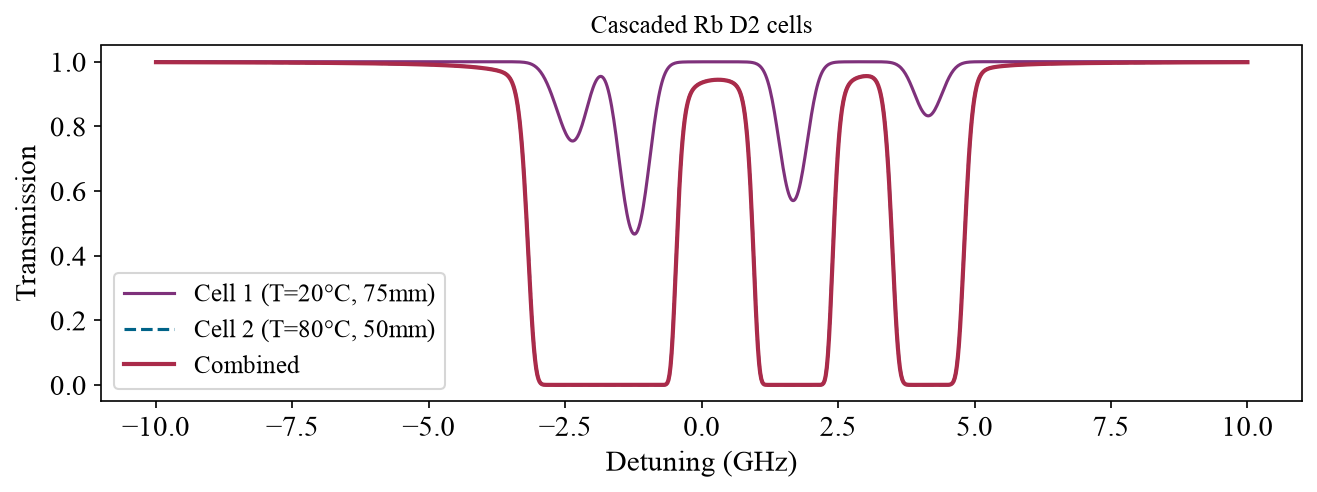

In [2]:
p1 = {'Elem':'Rb','Dline':'D2','T':20.,'lcell':75e-3,'Bfield':0}
p2 = {'Elem':'Rb','Dline':'D2','T':80.,'lcell':50e-3,'Bfield':0}

(S0_1,), (S0_2,) = em.calculate_cascade(det, [1,0,0], p1, p2, outputs=['S0'])
S0_combined = S0_1 * S0_2

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(det/1e3, S0_1, label='Cell 1 (T=20°C, 75mm)')
ax.plot(det/1e3, S0_2, label='Cell 2 (T=80°C, 50mm)', ls='--')
ax.plot(det/1e3, S0_combined, label='Combined', lw=2)
ax.set(xlabel='Detuning (GHz)', ylabel='Transmission')
ax.legend()
ax.set_title('Cascaded Rb D2 cells')
plt.tight_layout()


## Faraday atomic bandpass filter

The Faraday anomalous dispersion optical filter (FADOF) places a vapour cell
in a magnetic field between crossed polarisers (PBS → cell → PBS).

Here we model this as:
1. Cell 1 — Rb in B-field, performs Faraday rotation
2. 'Cell 2' — a crossed polariser (equivalent to selecting the y-polarised output)

Instead, we use `calculate()` directly and extract `Iy` (the y-polarised
intensity after the analyser), which peaks where rotation = 90°.

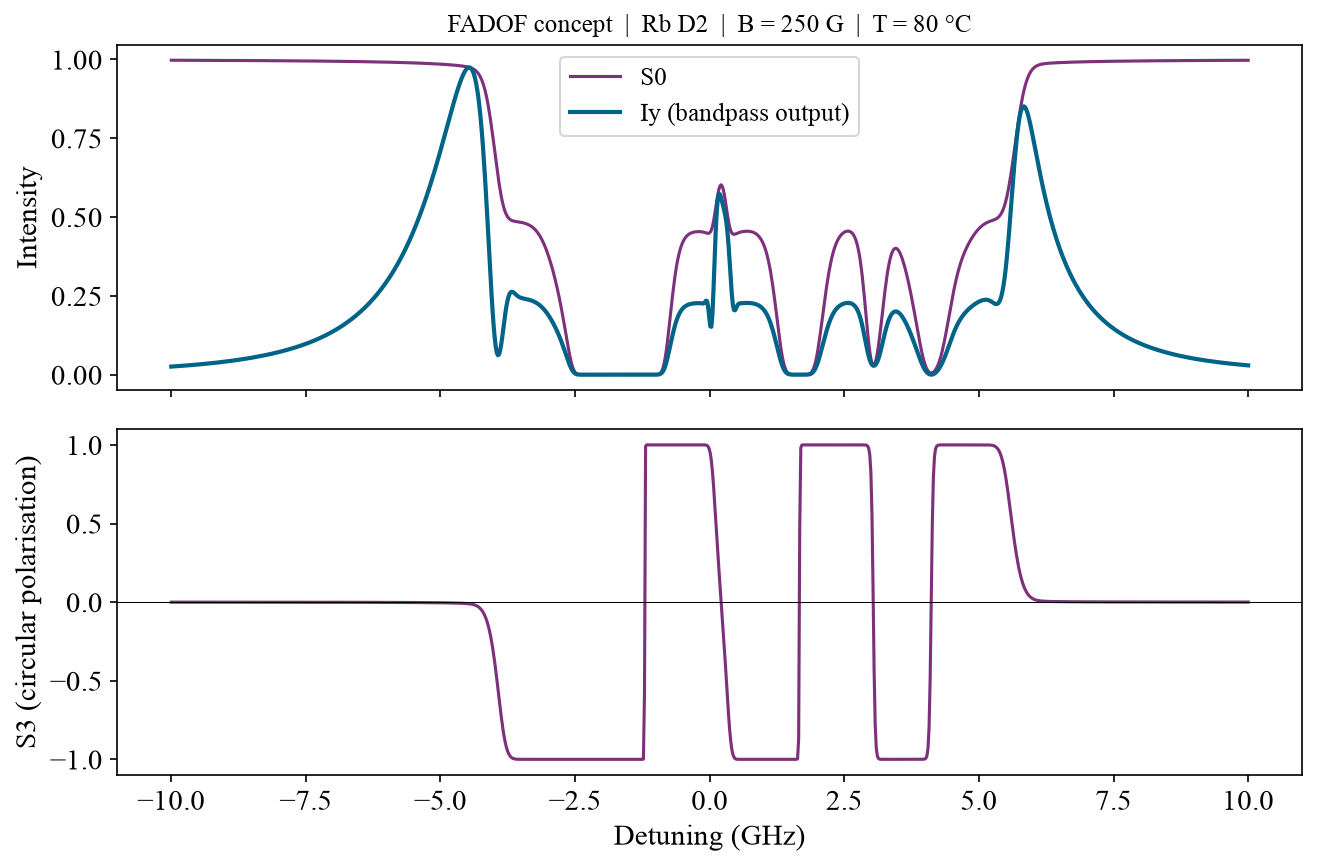

In [3]:
p_filter = {'Elem':'Rb','Dline':'D2','T':80.,'lcell':75e-3,'Bfield':250}
S0, Ix, Iy, S3 = em.calculate(det, [1,0,0], p_filter, outputs=['S0','Ix','Iy','S3'])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax1.plot(det/1e3, S0, label='S0')
ax1.plot(det/1e3, Iy, label='Iy (bandpass output)', lw=2)
ax1.set_ylabel('Intensity')
ax1.legend()
ax1.set_title('FADOF concept  |  Rb D2  |  B = 250 G  |  T = 80 °C')

ax2.plot(det/1e3, S3)
ax2.set(xlabel='Detuning (GHz)', ylabel='S3 (circular polarisation)')
ax2.axhline(0, color='k', lw=0.5)
plt.tight_layout()


## Cascaded MOF filter section (intermediate polariser)

`calculate_cascade` can place a **linear polariser between the two cells** via
`polariser_angle` (radians from *x*; `np.pi/2` = crossed with respect to an
*x*-polarised input) — the standard magneto-optical-filter (MOF) topology. A
**transformation cell** with a magnetic field rotates the polarisation on
resonance so it survives the crossed polariser, while a field-free
**extinction cell** removes residual on-resonance light.

With `polariser_angle` set, the **cell-2 outputs are already instrument totals**
normalised to the *original* input — you plot them directly, with no
combination rule and no 0/0 in the opaque wings.

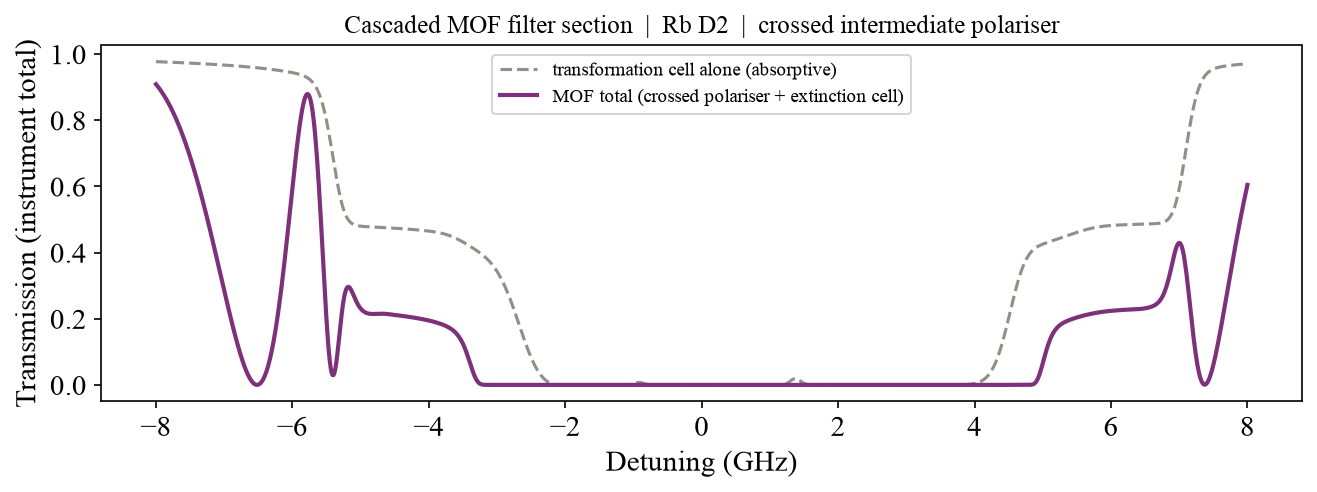

In [4]:
det_mof = np.linspace(-8_000, 8_000, 1200)

pA = {'Elem':'Rb', 'Dline':'D2', 'T':140., 'lcell':5e-3,  'Bfield':600}  # transformation cell (short, strong rotation)
pB = {'Elem':'Rb', 'Dline':'D2', 'T':120., 'lcell':25e-3, 'Bfield':0}    # field-free extinction cell

# crossed intermediate polariser -> cell-2 output is the instrument total
_, (S0_mof,) = em.calculate_cascade(
    det_mof, [1, 0, 0], pA, pB, outputs=['S0'], polariser_angle=np.pi/2)

# reference: the transformation cell on its own is purely absorptive
[S0_cell1] = em.calculate(det_mof, [1, 0, 0], pA, outputs=['S0'])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(det_mof/1e3, S0_cell1.real, ls='--', color=d_grey,
        label='transformation cell alone (absorptive)')
ax.plot(det_mof/1e3, S0_mof.real, lw=2, color=d_purple,
        label='MOF total (crossed polariser + extinction cell)')
ax.set(xlabel='Detuning (GHz)', ylabel='Transmission (instrument total)',
       title='Cascaded MOF filter section  |  Rb D2  |  crossed intermediate polariser')
ax.legend(fontsize=9)
plt.tight_layout()

## Polarisation propagation through two cells

When cell 1 has a B-field (Faraday effect), the output light is elliptically
polarised.  Cell 2 then sees a different input polarisation state, which
modifies its absorption.  `calculate_cascade` handles this automatically by
passing the full `E_out` vector from cell 1 to cell 2.

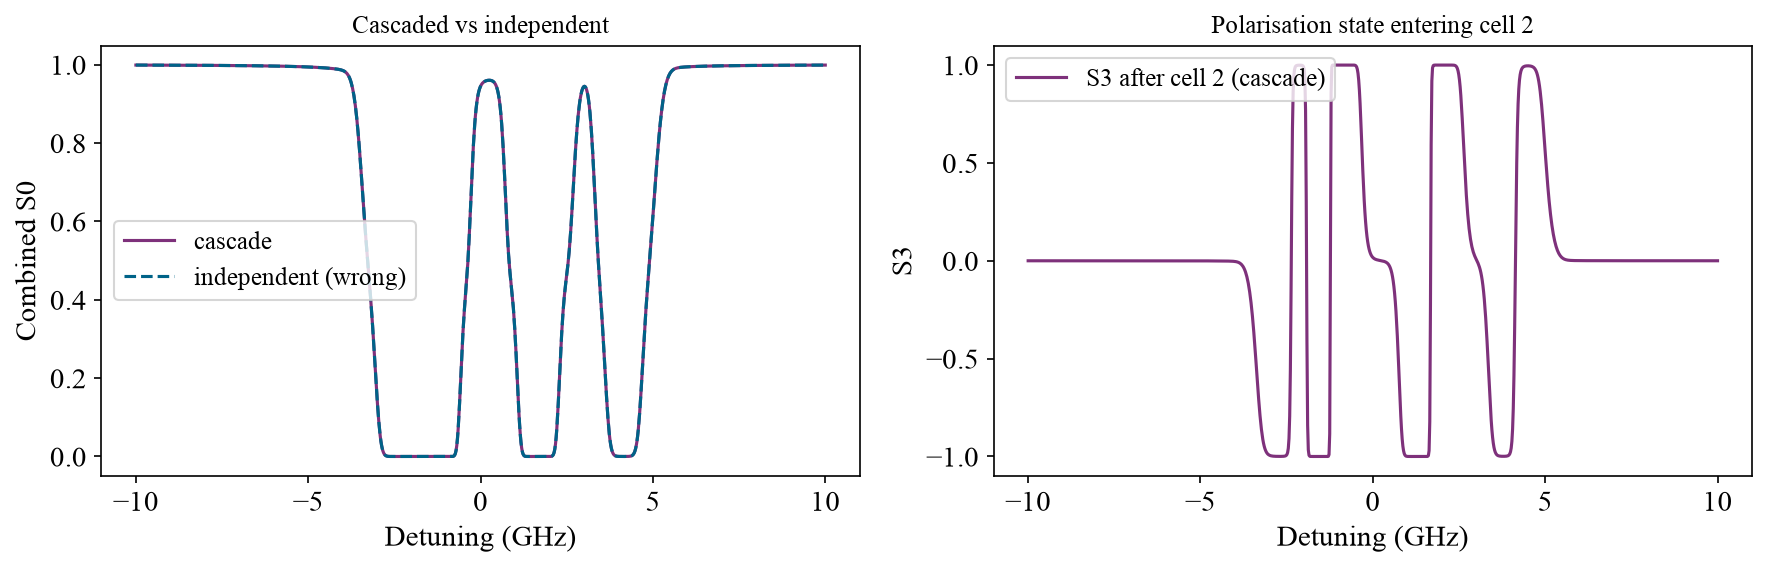

In [5]:
p1_B = {'Elem':'Rb','Dline':'D2','T':60.,'lcell':75e-3,'Bfield':150}
p2_B = {'Elem':'Rb','Dline':'D2','T':60.,'lcell':75e-3,'Bfield':0}

(S0_c1, S3_c1), (S0_c2, S3_c2) = em.calculate_cascade(
    det, [1,0,0], p1_B, p2_B, outputs=['S0','S3'])

# Compare with two independent single-cell calculations
S0_ind1, = em.calculate(det, [1,0,0], p1_B, outputs=['S0'])
S0_ind2, = em.calculate(det, [1,0,0], p2_B, outputs=['S0'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(det/1e3, S0_c1 * S0_c2, label='cascade')
axes[0].plot(det/1e3, S0_ind1 * S0_ind2, ls='--', label='independent (wrong)')
axes[0].set(xlabel='Detuning (GHz)', ylabel='Combined S0',
             title='Cascaded vs independent')
axes[0].legend()

axes[1].plot(det/1e3, S3_c2, label='S3 after cell 2 (cascade)')
axes[1].set(xlabel='Detuning (GHz)', ylabel='S3',
             title='Polarisation state entering cell 2')
axes[1].legend()
plt.tight_layout()


## Two cells with opposite fields

Placing cells with opposite B-fields in series is a way to cancel Faraday
rotation while keeping differential absorption.  This is used in some
magnetometry and EIT schemes.

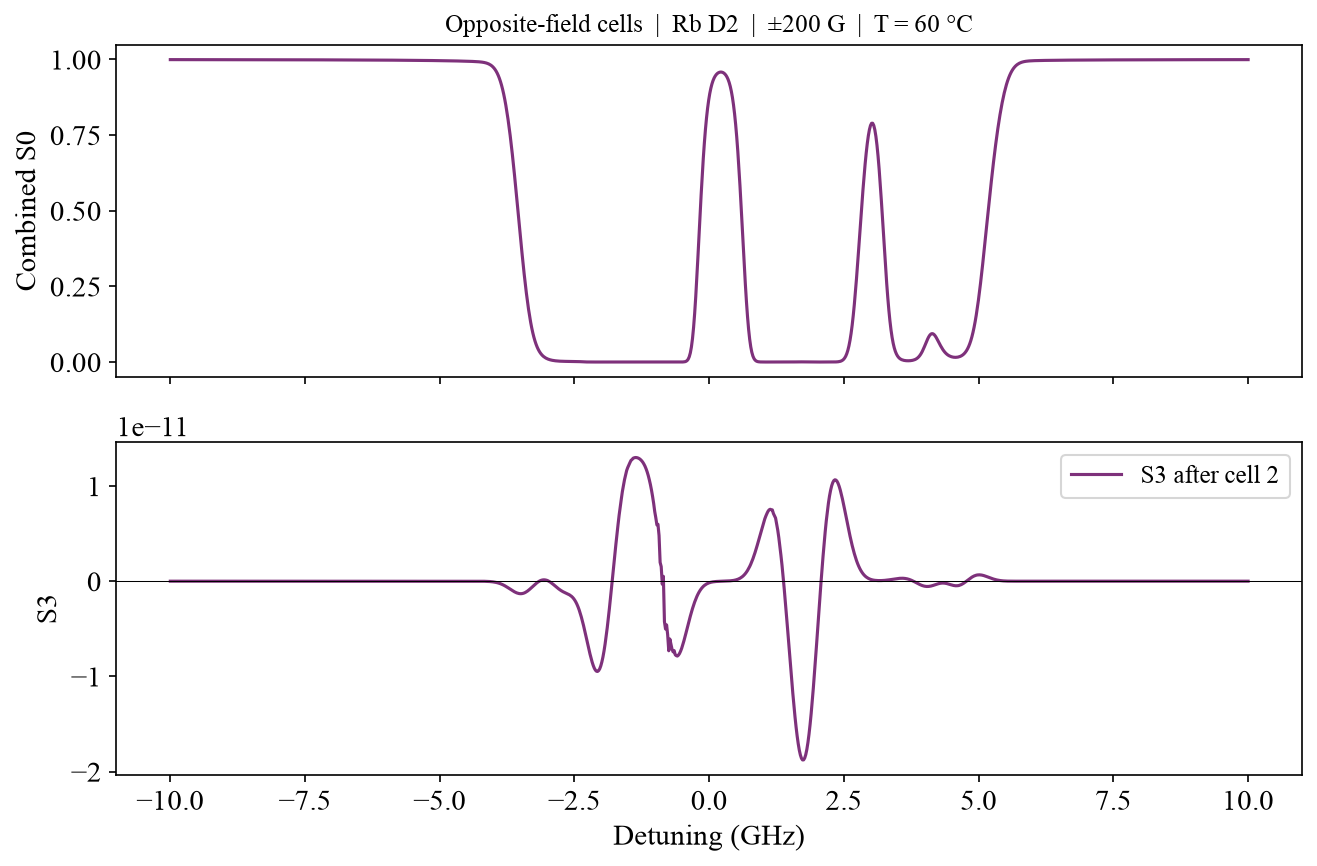

In [6]:
p_pos = {'Elem':'Rb','Dline':'D2','T':60.,'lcell':50e-3,'Bfield':200}
p_neg = {'Elem':'Rb','Dline':'D2','T':60.,'lcell':50e-3,'Bfield':-200}

(S0_p, S3_p), (S0_n, S3_n) = em.calculate_cascade(
    det, [1,0,0], p_pos, p_neg, outputs=['S0','S3'])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax1.plot(det/1e3, S0_p * S0_n)
ax1.set_ylabel('Combined S0')
ax1.set_title('Opposite-field cells  |  Rb D2  |  ±200 G  |  T = 60 °C')
ax2.plot(det/1e3, S3_n, label='S3 after cell 2')
ax2.axhline(0, color='k', lw=0.5)
ax2.set(xlabel='Detuning (GHz)', ylabel='S3')
ax2.legend()
plt.tight_layout()
